## Free energy

In [1]:
import cupy as cp
import matplotlib.pyplot as plt

from tqdm.notebook import tqdm     

import seaborn as sns 

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "axes.labelsize": 12,
    "font.size": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})


In [2]:

q = 4
J_corsivo = 1
J = J_corsivo * 2**((q-1)/2) / cp.sqrt(q)
x = 0.5
M=100 # Number of iterations for the solver

T_in = 0.001
T_out = 0.04


In [ ]:
T_range = cp.linspace(T_in, T_out, 30)
F = cp.empty(T_range.size, dtype=cp.float64)

S = 2**(int(cp.log2(100000))+1)
N_max = (S-1) // 4

n = cp.fft.fftfreq(S)*S
dealias_mask = cp.abs(n+0.5) <= N_max
freq_shift = cp.exp(-1j * cp.pi * n / S) 

for k in range(T_range.size):
    
    T = T_range[k]
    beta = 1/T
    x = 0.5

    t_values = (cp.arange(S) + 0.5) * beta / S

    omega = 2*cp.pi/beta*(n + 0.5)
    phase_shift = cp.exp(-1j*cp.pi/beta*t_values)

    G_t = cp.full(t_values.size, 0.5)
    G = 1.0 / (1j*omega)
    G_free = G

    diff = cp.empty((M), dtype=cp.float64)

    for i in range(M):
        if i>= 2:
            check = diff[i-1]-diff[i-2]
            if check > 0:
                x = x/2.0

        Sigma_t = J**2 *cp.power(G_t, q-1)
        Sigma = cp.fft.fft(Sigma_t * phase_shift) * freq_shift
        Sigma *= dealias_mask
        Sigma *= beta/S
        

        G_new = (1-x)*G + x/(1j*omega-Sigma)
        Delta_G = G_new - G_free
        Delta_G *= dealias_mask

        G_new_t = 0.5 + cp.real(S/beta * cp.fft.ifft(Delta_G / freq_shift) * phase_shift.conj())
        diff[i] = cp.sum(cp.abs(G_new_t-G_t)**2)*beta/S

        G = G_new
        G_t = G_new_t

    Sigma_t = J**2 *cp.power(G_t, q-1)
    Sigma = cp.fft.fft(Sigma_t * phase_shift) * freq_shift
    Sigma *= dealias_mask
    Sigma *= beta/S

    p1 = cp.sum(cp.log((1j*omega - Sigma)/(1j*omega)))
    p2 = cp.sum(Sigma*G[::-1])

    F[k] = (-T/2*(cp.log(2) + p1 -(1-1/q)*p2)).real

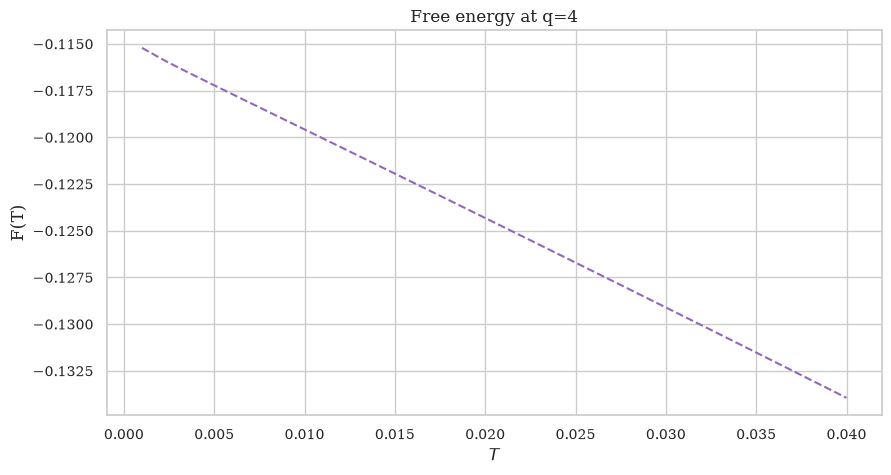

In [6]:
T_range_CPU = T_range.get()
F_CPU = F.get()


plt.figure(figsize=(10, 5))
plt.plot(T_range_CPU, 2*F_CPU, color="tab:purple", linestyle ='--')


plt.xlabel(fr'$T$')
plt.ylabel(fr'F(T)')
plt.title(fr'Free energy at q={q}')

plt.show()